In [1]:
import numpy as np
from gwlens.lens import nfw
import matplotlib.pyplot as plt
from gwlens.tools import plotting
from gwlens.tools import halo
import astropy.units as u
from glow import time_domain_c, freq_domain_c, lenses
from gwlens.lens import nfw


plotting.apply_figure_style()


In [2]:

print("K fixed value is ", k_fixed)
yi = 0.05
w_val = np.linspace(0.001, 100, 300)
F_go = np.array([nfw_lens.Amplification(w = wi,y = yi,rs=0.1) for wi in w_val])
plt.plot(w_val, np.abs(F_go), label='GWLENS')
plt.xscale("log")

NameError: name 'k_fixed' is not defined

{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0
{'eps_soft': 1e-15, 'eps_NFW': 0.01}
2000.0
2000.0
2000.0


Text(0.5, 1.0, 'NFW , $\\xi_0/r_s = 0.163$, $M_v = 10^{9} M_{\\odot}$')

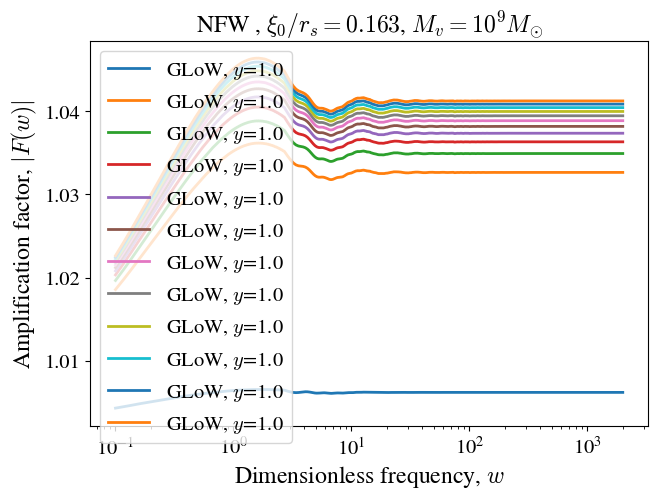

In [3]:
nfw_lens = nfw.NFW1()  #GWLENS NFW class initiation

lens_virial_mass =  np.linspace(1e+3, 1e+12, 12)
for m in lens_virial_mass:

    Halo = halo.NFW(M200 = m, zl = 1.0)
    k_fixed = Halo.scaling_ratio(zs=2.0).value


    Psi_cls = lenses.Psi_NFW
    Psi_tmp = Psi_cls()
    p_phys_default, p_prec_default = Psi_tmp.default_params()
    print(p_prec_default)
    p_phys = dict(p_phys_default)
    p_phys['name'] = 'NFW'
    p_phys['psi0'] = 1.0
    p_phys['xs']   = 1 /k_fixed

    p_prec = dict(p_prec_default)
    p_prec['eps_soft'] = 1e-17
    p_prec['eps_NFW']  = 0.001
    #p_prec['tmin'] = 0.001

    for yi in np.array([0.01,0.1,1.0]):

        Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)
        It_nfw  = time_domain_c.It_SingleIntegral_C(Psi_nfw, yi, p_prec={'tmax':1e+5})
        Fw_nfw  = freq_domain_c.Fw_FFT_C(It_nfw,p_prec={'wmin':0.1,'wmax':2000})
        w_glow  = Fw_nfw.w_grid
        print(w_glow[-1])
    plt.semilogx(w_glow, np.abs(Fw_nfw.eval_Fw(w_glow)),lw=2, label=f"GLoW, $y$={yi}")
plt.legend()
plt.xlabel("Dimensionless frequency, $w$")
plt.ylabel("Amplification factor, $|F(w)|$")
plt.title("NFW , $\\xi_0/r_s = 0.163$, $M_v = 10^{9} M_{\\odot}$")

[1.00000000e+03 9.09090918e+10 1.81818183e+11 2.72727273e+11
 3.63636364e+11 4.54545455e+11 5.45454546e+11 6.36363637e+11
 7.27272728e+11 8.18181818e+11 9.09090909e+11 1.00000000e+12]


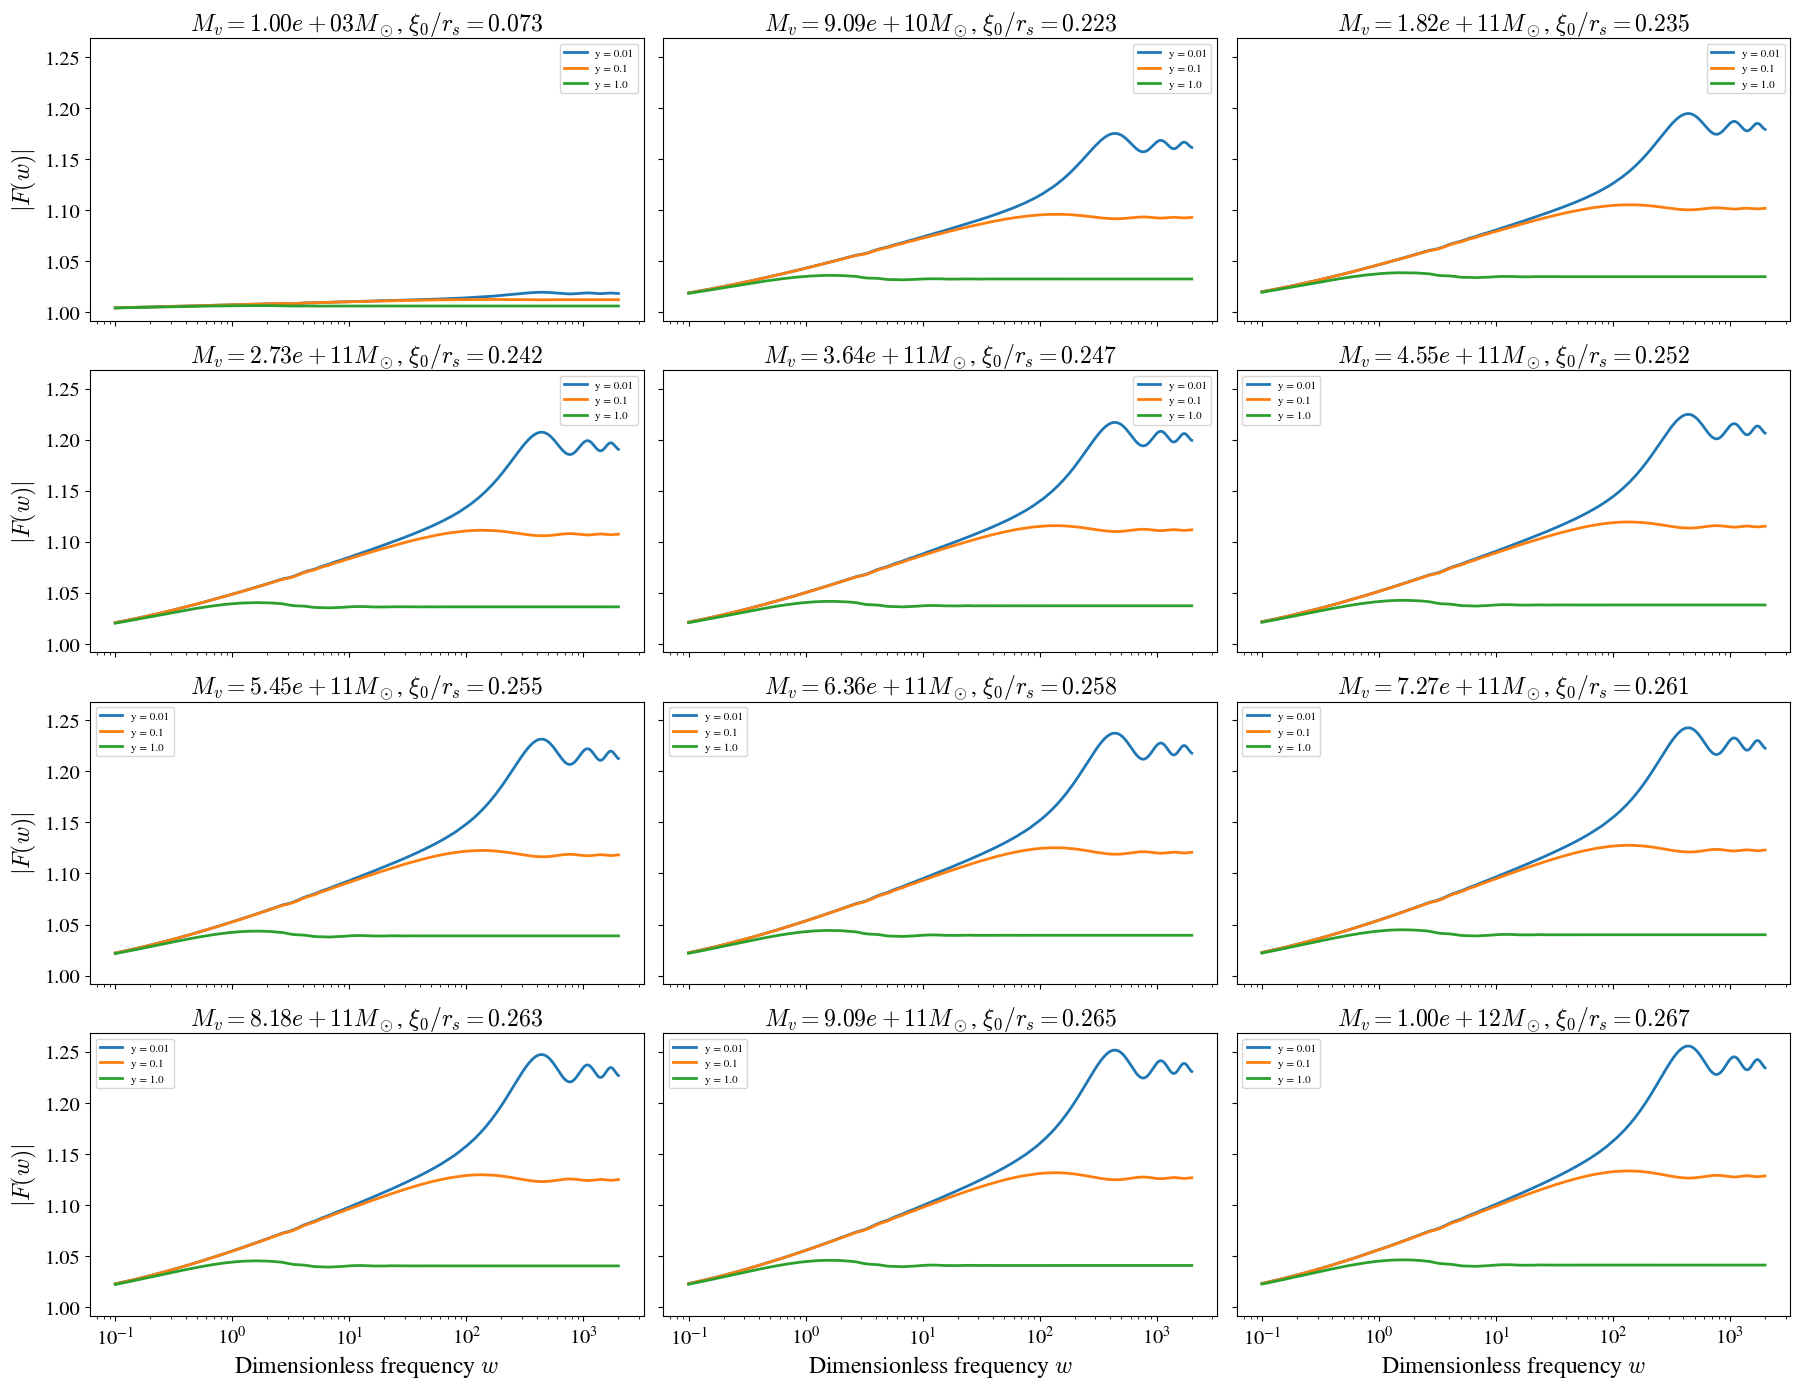

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

nfw_lens = nfw.NFW1()

lens_virial_mass = np.arange(1e3,1e12,10) #np.linspace(1e3, 1e12, 12)
print(lens_virial_mass)
fig, axes = plt.subplots(4, 3, figsize=(18, 14), sharex=True, sharey=True)
axes = axes.flatten()

yi_values = np.array([0.01, 0.1, 1.0])

for i, m in enumerate(lens_virial_mass):

    ax = axes[i]

    Halo = halo.NFW(M200=m, zl=1.0)
    k_fixed = Halo.scaling_ratio(zs=2.0).value

    Psi_cls = lenses.Psi_NFW
    Psi_tmp = Psi_cls()
    p_phys_default, p_prec_default = Psi_tmp.default_params()

    p_phys = dict(p_phys_default)
    p_phys['name'] = 'NFW'
    p_phys['psi0'] = 1.0
    p_phys['xs'] = 1 / k_fixed

    p_prec = dict(p_prec_default)
    p_prec['eps_soft'] = 1e-17
    p_prec['eps_NFW'] = 0.001

    for yi in yi_values:

        Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)
        It_nfw = time_domain_c.It_SingleIntegral_C(Psi_nfw, yi, p_prec={'tmax': 1e5})
        Fw_nfw = freq_domain_c.Fw_FFT_C(It_nfw, p_prec={'wmin': 0.1, 'wmax': 2000})

        w_glow = Fw_nfw.w_grid

        ax.semilogx(
            w_glow,
            np.abs(Fw_nfw.eval_Fw(w_glow)),
            lw=2,
            label=f"y = {yi}"
        )

    ax.set_title(
        rf"$M_v = {m:.2e} M_\odot$, $\xi_0/r_s  = {k_fixed:.3f}$"
    )

    ax.legend(fontsize=8)

# Axis labels (clean layout)
for ax in axes[-3:]:
    ax.set_xlabel("Dimensionless frequency $w$")

for ax in axes[::3]:
    ax.set_ylabel(r"$|F(w)|$")

plt.tight_layout()
plt.show()

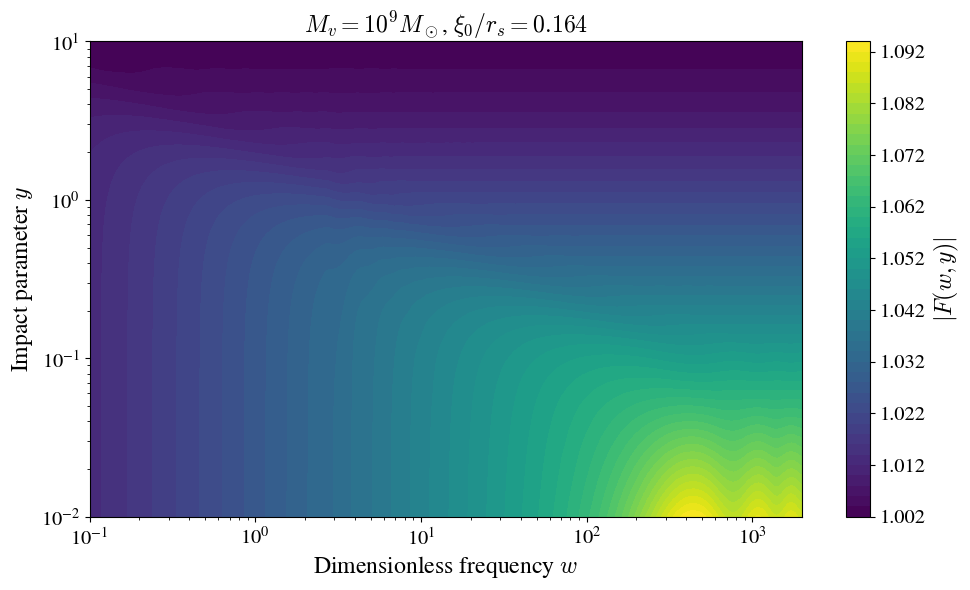

In [69]:
import numpy as np
import matplotlib.pyplot as plt

# --- fixed mass ---
m = 1e9

# --- halo setup ---
Halo = halo.NFW(M200=m, zl=1.0)
k_fixed = Halo.scaling_ratio(zs=2.0).value

Psi_cls = lenses.Psi_NFW
Psi_tmp = Psi_cls()
p_phys_default, p_prec_default = Psi_tmp.default_params()

p_phys = dict(p_phys_default)
p_phys['name'] = 'NFW'
p_phys['psi0'] = 1.0
p_phys['xs'] = 1 / k_fixed

p_prec = dict(p_prec_default)
p_prec['eps_soft'] = 1e-17
p_prec['eps_NFW'] = 0.001

# --- grids ---
y_vals = np.logspace(-2, 1, 50)      # 0.01 → 1
w_vals = np.logspace(-1, 3.3, 200)   # ~0.1 → 2000

F_map = np.zeros((len(y_vals), len(w_vals)))

# --- compute map ---
for i, y in enumerate(y_vals):

    Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)
    It_nfw = time_domain_c.It_SingleIntegral_C(
        Psi_nfw, y, p_prec={'tmax': 1e5}
    )
    Fw_nfw = freq_domain_c.Fw_FFT_C(
        It_nfw, p_prec={'wmin': 0.1, 'wmax': 2000}
    )

    # evaluate once per y
    F_vals = np.abs(Fw_nfw.eval_Fw(w_vals))
    F_map[i, :] = F_vals

# --- contour plot ---
W, Y = np.meshgrid(w_vals, y_vals)

plt.figure(figsize=(10, 6))
cp = plt.contourf(W, Y, F_map, levels=50, cmap="viridis")

plt.xscale("log")
plt.yscale("log")

plt.colorbar(cp, label=r"$|F(w, y)|$")

plt.xlabel(r"Dimensionless frequency $w$")
plt.ylabel(r"Impact parameter $y$")

plt.title(
    
    rf"$M_v = 10^9 M_\odot$, $\xi_0/r_s  = {k_fixed:.3f}$"
)

plt.tight_layout()
plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# fixed mass
# -----------------------------
m = 1e9

Halo = halo.NFW(M200=m, zl=1.0)
k_fixed = Halo.scaling_ratio(zs=2.0).value

Psi_cls = lenses.Psi_NFW
Psi_tmp = Psi_cls()
p_phys_default, p_prec_default = Psi_tmp.default_params()

p_phys = dict(p_phys_default)
p_phys['name'] = 'NFW'
p_phys['psi0'] = 1.0
p_phys['xs'] = 1 / k_fixed

p_prec = dict(p_prec_default)
p_prec['eps_soft'] = 1e-17
p_prec['eps_NFW'] = 0.001

# -----------------------------
# grids
# -----------------------------
y_vals = np.logspace(-2, 0, 40)
w_vals = np.logspace(-1, 3.3, 200)

# -----------------------------
# storage
# -----------------------------
F_wave = np.zeros((len(y_vals), len(w_vals)))
F_geo  = np.zeros(len(y_vals))   # geometric optics only y-dependent

# -----------------------------
# loop over y
# -----------------------------
for i, y in enumerate(y_vals):

    Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)

    # wave optics
    It_nfw = time_domain_c.It_SingleIntegral_C(Psi_nfw, y, p_prec={'tmax': 1e5})
    Fw_nfw = freq_domain_c.Fw_FFT_C(It_nfw, p_prec={'wmin': 0.1, 'wmax': 2000})

    F_wave[i, :] = np.abs(Fw_nfw.eval_Fw(w_vals))

    # -----------------------------
    # geometric optics (YOU MAY REPLACE THIS)
    # -----------------------------
    # OPTION A: if library has it:
    # F_geo[i] = lenses.geometric_magnification_NFW(y, p_phys, p_prec)
    for j, w in enumerate(w_vals):
        F_geo[i, j] = nfw_lens.geometric_optics_amplification(
            w=w, y1=y, y2=0, rs=0.1
        )
    # OPTION B: placeholder fallback (NOT physical, replace if possible)
    F_geo[i] = np.max(F_wave[i, :])  # temporary proxy only

# -----------------------------
# build deviation map
# -----------------------------
W, Y = np.meshgrid(w_vals, y_vals)

F_geo_grid = np.repeat(F_geo[:, None], len(w_vals), axis=1)

deviation = np.abs(F_wave - F_geo_grid) / (F_geo_grid + 1e-30)

# -----------------------------
# mask wave-optics region (>10%)
# -----------------------------
wave_region = deviation > 0.1

# -----------------------------
# plot
# -----------------------------
plt.figure(figsize=(10, 6))

plt.contourf(W, Y, F_wave, levels=50, cmap="viridis")
plt.colorbar(label=r"$|F_{\mathrm{wave}}(w,y)|$")

# overlay boundary of 10% deviation
plt.contour(W, Y, wave_region, levels=[0.5], colors="red", linewidths=2)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Dimensionless frequency $w$")
plt.ylabel(r"Impact parameter $y$")

plt.title(

    rf"$\xi_0/r_s = {k_fixed:.3f}$"
    
)

plt.show()

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

[1.03036662 1.03029459 1.03023546 1.03039422 1.03022044 1.03031662
 1.03034931 1.03020518 1.03038392 1.03026583 1.03026034 1.03038648
 1.03020693 1.03034419 1.03032238 1.03021713 1.03039333 1.03024009
 1.0302887  1.03037061 1.03020185 1.0303675  1.03029325 1.03023655
 1.03039396 1.03021974 1.03031792 1.0303481  1.03020567 1.03038441
 1.03026462 1.03026163 1.03038578 1.03020666 1.03034528 1.03032103
 1.03021802 1.03039336 1.03023915 1.03029006 1.03036955 1.03020205
 1.03036826 1.03029192 1.03023774 1.03039352 1.03021919 1.03031917
 1.0303468  1.03020632 1.03038474 1.03026347 1.030263   1.03038492
 1.03020656 1.03034629 1.03031964 1.03021906 1.03039321 1.03023832
 1.03029142 1.03036837 1.03020243 1.03036889 1.03029061 1.03023905
 1.03039292 1.03021878 1.03032039 1.03034542 1.03020715 1.03038492
 1.0302624  1.03026442 1.03038391 1.03020664 1.0303472  1.03031823
 1.03022024 1.0303929  1.03023761 1.0302928  1.03036706 1.03020299
 1.03036939 1.03028932 1.03024045 1.03039213 1.03021852 1.0303

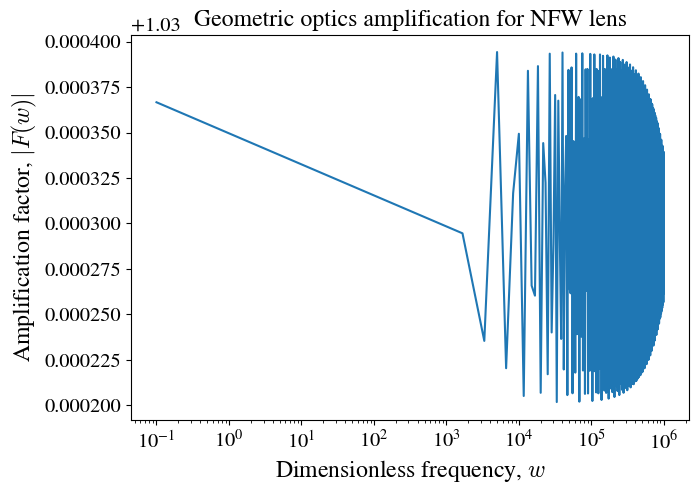

In [36]:
nfw_lens = nfw.NFW1()
F = []
w_values = np.linspace(0.1, 1e+6, 600)
for wi in w_values:
    F.append(nfw_lens.Amplification(w=wi, y=0.1, rs=0.12))
    
plt.plot(w_values, np.abs(F))
plt.xscale("log")
plt.xlabel("Dimensionless frequency, $w$")
plt.ylabel("Amplification factor, $|F(w)|$")
plt.title("Geometric optics amplification for NFW lens")
#plt.ylim(0,2)
print(np.abs(F))

/work/sreekanth/codes/GWLENS/gwlens/lens/nfw.py:469: RuntimeWarning: divide by zero encountered in arctanh
  h = np.arctanh(s) / s


AttributeError: 'NFW1' object has no attribute 'It_SingleIntegral_C'

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# fixed mass
# -----------------------------
m = 1e9

Halo = halo.NFW(M200=m, zl=1.0)
k_fixed = Halo.scaling_ratio(zs=2.0).value

Psi_cls = lenses.Psi_NFW
Psi_tmp = Psi_cls()
p_phys_default, p_prec_default = Psi_tmp.default_params()

p_phys = dict(p_phys_default)
p_phys['name'] = 'NFW'
p_phys['psi0'] = 1.0
p_phys['xs'] = 1 / k_fixed

p_prec = dict(p_prec_default)
p_prec['eps_soft'] = 1e-17
p_prec['eps_NFW'] = 0.001

# -----------------------------
# grids
# -----------------------------
y_vals = np.logspace(-2, 0, 40)
w_vals = np.logspace(-1, 3.3, 200)

# -----------------------------
# storage (FIXED SHAPES)
# -----------------------------
F_wave = np.zeros((len(y_vals), len(w_vals)))
F_geo  = np.zeros((len(y_vals), len(w_vals)))   # FIXED: must be 2D

# -----------------------------
# loop over y
# -----------------------------
for i, y in enumerate(y_vals):

    Psi_nfw = lenses.Psi_NFW(p_phys=p_phys, p_prec=p_prec)

    # -----------------------------
    # wave optics
    # -----------------------------
    It_nfw = time_domain_c.It_SingleIntegral_C(
        Psi_nfw, y, p_prec={'tmax': 1e5}
    )

    Fw_nfw = freq_domain_c.Fw_FFT_C(
        It_nfw,
        p_prec={'wmin': w_vals.min(), 'wmax': w_vals.max()}
    )

    F_wave[i, :] = np.abs(Fw_nfw.eval_Fw(w_vals))

    # -----------------------------
    # geometric optics (CORRECT)
    # -----------------------------
    for j, w in enumerate(w_vals):
        F_geo[i, j] = nfw_lens.geometric_optics_amplification(
            w=w,
            y1=y,
            y2=0,
            rs=0.1
        )

# -----------------------------
# build deviation map
# -----------------------------
deviation = np.abs(F_wave - np.abs(F_geo)) / (np.abs(F_geo) + 1e-30)

wave_region = deviation < 0.1

# -----------------------------
# meshgrid for plotting
# -----------------------------
W, Y = np.meshgrid(w_vals, y_vals)

# -----------------------------
# plot
# -----------------------------
plt.figure(figsize=(10, 6))

# wave optics amplitude
plt.contourf(W, Y, F_wave, levels=50, cmap="viridis")
plt.colorbar(label=r"$|F_{\mathrm{wave}}(w,y)|$")

# 10% deviation boundary
plt.contour(W, Y, deviation, levels=[0.1], colors="red", linewidths=2)

plt.xscale("log")
plt.yscale("log")

plt.xlabel(r"Dimensionless frequency $w$")
plt.ylabel(r"Impact parameter $y$")

plt.title(rf"NFW lens: $\xi_0/r_s = {k_fixed:.3f}$")

plt.tight_layout()
plt.show()

/tmp/ipykernel_31366/3417712824.py:62: ComplexWarning: Casting complex values to real discards the imaginary part
  F_geo[i, j] = nfw_lens.geometric_optics_amplification(


KeyboardInterrupt: 